# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 14: Cross-Dataset Evaluation

### Objective

A recognizer that works on the dataset it was trained on may fail on another one: a different sensor, different lighting, a different population. This notebook measures how well the models **transfer to a dataset they never saw**:

```text
Train on CASIA-Iris-Thousand   ->   Test on IIT Delhi (never seen, never used for any decision)
```

The notebook must:

1. Evaluate every trained recognizer of Notebook 07 (baselines) and Notebook 13 (final models) on the unseen dataset.
2. Measure **Rank-1 accuracy**, **verification accuracy**, **EER**, and **TAR @ FAR**.
3. Show how much is lost compared with the same model on the training dataset (the **domain gap**), including whether the **operating threshold transfers**.
4. Compare the final model with the baselines and the same-code control, with the best model of each kind chosen **only on the training dataset's validation people**.

### Important boundary of this notebook

This notebook performs **evaluation only**.

It does not train or tune anything. Every model was trained on the source dataset alone (the notebook asserts this from each checkpoint). The unseen dataset is used for scoring only: **not** for choosing a model, a threshold, or any setting.

## 1. Research rationale

### 1.1 What cross-dataset evaluation tests

All models were trained on **CASIA-Iris-Thousand only** (Notebooks 07 and 13; the synthetic images of Notebook 10 were generated only for CASIA training identities). A second dataset differs in sensor, resolution, illumination, and population. If a model has learned iris texture, its embeddings should still separate people there; if it has learned the quirks of the training sensor, accuracy collapses. This is the third hypothesis of the proposal: a model trained with synthetic augmentation **generalizes better across sensors and datasets**.

### 1.2 The protocol (identical to Notebooks 07 and 13)

| Evaluation set | Data | Role |
|---|---|---|
| `<source>/val` | unseen people of the training dataset | Calibrates the operating threshold; picks the best model of each kind |
| `<source>/test` | other unseen people of the training dataset | **Within-dataset reference** |
| `<target>/cross_dataset` | the other dataset (all its splits by default) | **The cross-dataset result** |

Gallery = the `K` support images of each class, averaged into one prototype; probes = the query images; score = cosine similarity. The functions, the seed (`EVAL_SEED`), and the 5-way episodes are the same as in Notebooks 07 and 13, so the numbers can be **compared with the stored ones, and the notebook checks that they agree**.

### 1.3 The four measures

| Measure | Definition |
|---|---|
| **Rank-1 accuracy** | A probe is correct if its most similar prototype, among **all** classes of the set, is its own class |
| **Verification accuracy** | **Balanced** accuracy of the accept/reject decision at a threshold `t`: `(TAR + TRR) / 2 = 1 - (FAR + FRR) / 2`, with TAR = share of same-person pairs accepted and FAR = share of different-person pairs accepted |
| **EER** | The error rate where false accept equals false reject (threshold-free) |
| **TAR @ FAR** | True accept rate at a fixed false accept rate (1e-1, 1e-2, 1e-3, 1e-4; reported as `NaN` when there are too few impostor scores to resolve that FAR) |

Plain accuracy is not used for verification: different-person pairs outnumber same-person pairs by hundreds to one, so a decision that accepts nobody would look excellent.

### 1.4 Does the threshold transfer?

A deployed system uses one threshold. If it is chosen on the training dataset, a dataset shift can move the score distributions so that the same threshold accepts too many or too few people, even if the EER is still good. Three verification accuracies are therefore reported on every set:

| Name | Threshold from | Meaning |
|---|---|---|
| `verification_acc_src_eer` | the **EER point of the source validation people** | **The honest number**: a threshold chosen without ever seeing the target |
| `verification_acc_src_far` | the point where **1% of source-validation impostors** are accepted | The same idea with a security-oriented operating point |
| `verification_acc_oracle` | the best threshold **on the evaluated set itself** | An **optimistic upper bound**. Never report it as the result |

The gap between the first and the third is the cost of the threshold not transferring. `threshold_shift` is the difference between the set's own EER threshold and the source one, and `dprime` (separation of the same-person and different-person score distributions) shows how much the shift hurts.

### 1.5 Choosing the models to report

For every kind of model (Notebook 07 real only, Notebook 07 traditional augmentation, same-code control, final real + synthetic) and every shot, the backbone and loss variant with the **lowest mean validation EER on the source dataset** is reported. The target dataset plays no part in the choice, so the cross-dataset numbers are not inflated by picking the best of many.

### 1.6 Things to keep in mind

- **One direction only** (source to target). The reverse direction would need every model retrained on the second dataset.
- **The target has fewer people**, so its numbers are less certain than the source's. Confidence intervals and significance tests are Notebook 18.
- **Notebook 07 used random batches** and Notebook 13 class-balanced ones, so differences between them also contain the sampler. The same-code control (if you trained it) isolates the effect of the synthetic data.
- **Synthetic data helps only if** the final model beats the traditional-augmentation baseline too (the generator was trained on appearance-transformed views).
- **Run `QUICK_TEST = True` first.** **Windows:** no NumPy matrix multiplication is used; PyTorch is imported first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import hashlib
import json
import math
import re
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import models as tv_models
except ImportError as error:
    raise ImportError(
        "Notebook 14 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**: a finished evaluation is skipped on re-run only if its stored fingerprint and its checkpoint file are unchanged.

- `QUICK_TEST = True` evaluates the models of the quick tests of Notebooks 07 and 13 with small sample sizes and writes to a separate folder.
- `TRAIN_DATASETS` names the **source** dataset (exactly one). Every other dataset in the manifest is a **target**.
- `INCLUDE_BASELINES` / `INCLUDE_FINAL` and the filters (`BASELINE_VARIANTS`, `FINAL_DATA_VARIANTS`, `FINAL_LOSS_VARIANTS`, `BACKBONES`, `SEEDS`, `SHOTS_TO_RUN`) choose which checkpoints are evaluated; `None` means "everything found".
- `TARGET_SPLITS`: the target dataset was never trained on, so all its splits can serve as the evaluation set (the default, as in Notebooks 07 and 13).
- `FAR_TARGETS` are the false accept rates for TAR @ FAR; `SOURCE_FAR_TARGET` defines the second source-calibrated threshold.
- `MIXED_PRECISION` is on by default so that the embeddings are computed exactly as in Notebooks 07 and 13.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = True          # True = evaluate the quick-test models, small samples, separate folder

# ---- which models to evaluate ----
SHOTS_TO_RUN = [1, 2, 3, 5]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]    # the SOURCE dataset (exactly one)
INCLUDE_BASELINES = True                    # Notebook 07 checkpoints
BASELINE_VARIANTS = ["real_only", "real_traditional_aug"]
INCLUDE_FINAL = True                        # Notebook 13 checkpoints
FINAL_DATA_VARIANTS = ["real_plus_synthetic", "real_only"]
FINAL_LOSS_VARIANTS = None                  # None = every loss variant found
BACKBONES = None                            # None = every backbone found, e.g. ["efficientnet_b0"]
SEEDS = None                                # None = every seed found
UPSTREAM_FROM_QUICKTEST = QUICK_TEST        # QUICK_TEST reads the quick-test outputs of Notebooks 07 and 13

INPUT_HW = (64, 512)

# ---- target datasets ----
TARGET_SPLITS = ["train", "val", "test"]    # splits of the unseen dataset used as the evaluation set
EVALUATE_SOURCE_TEST = True                 # within-dataset reference (source test people)
MIN_TARGET_CLASSES = 5                      # a target set with fewer identities is not evaluated

# ---- protocol (identical to Notebooks 07 and 13) ----
EVAL_SEED = 2024
EPISODE_WAY = 5
NUM_EPISODES = 600
MAX_IMPOSTOR_SCORES = 5_000_000
FAR_TARGETS = [1e-1, 1e-2, 1e-3, 1e-4]
SOURCE_FAR_TARGET = 1e-2                    # second source-calibrated threshold (FAR on source validation)
MIXED_PRECISION = True                      # used only on CUDA
EMBED_BATCH_SIZE = 128

# ---- bookkeeping ----
RESUME = True

if QUICK_TEST:
    NUM_EPISODES = 100
    print("QUICK_TEST is ON: quick-test models of Notebooks 07 and 13, small samples, separate output folder.")

# ---- sanity checks on the configuration itself ----
assert len(TRAIN_DATASETS) == 1, "This notebook evaluates single-source training: TRAIN_DATASETS must name exactly one dataset"
assert tuple(INPUT_HW) == (64, 512), "This notebook assumes 64 x 512 iris strips"
assert set(BASELINE_VARIANTS) <= {"real_only", "real_traditional_aug"}, "Unknown baseline variant"
assert set(FINAL_DATA_VARIANTS) <= {"real_plus_synthetic", "real_only"}, "Unknown final data variant"
assert INCLUDE_BASELINES or INCLUDE_FINAL, "Nothing to evaluate: enable INCLUDE_BASELINES or INCLUDE_FINAL"
assert len(TARGET_SPLITS) >= 1 and set(TARGET_SPLITS) <= {"train", "val", "test"}, "TARGET_SPLITS must be a subset of train / val / test"
assert all(0.0 < f < 1.0 for f in FAR_TARGETS) and 0.0 < SOURCE_FAR_TARGET < 1.0
assert EMBED_BATCH_SIZE >= 1 and MIN_TARGET_CLASSES >= 2 and len(SHOTS_TO_RUN) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(MIXED_PRECISION and DEVICE.type == "cuda")

print("Source dataset:", TRAIN_DATASETS[0], "| shots:", SHOTS_TO_RUN, "| device:", DEVICE, "| mixed precision:", USE_AMP)
if DEVICE.type != "cuda":
    print("NOTE: no CUDA GPU found. Evaluation works on CPU but is slower, and tiny numerical differences from "
          "the GPU results of Notebooks 07 and 13 are possible.")

QUICK_TEST is ON: quick-test models of Notebooks 07 and 13, small samples, separate output folder.
Source dataset: CASIA-Iris-Thousand | shots: [1, 2, 3, 5] | device: cuda | mixed precision: True


In [4]:
# ============================================================
# 4b. Output and upstream locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
BASELINE_DIR = PROJECT_ROOT / "checkpoints" / f"baseline_recognition{upstream_suffix}"
FINAL_DIR = PROJECT_ROOT / "checkpoints" / f"final_recognition{upstream_suffix}"
BASELINE_RESULTS_PATH = PROJECT_ROOT / "results" / f"baseline_recognition{upstream_suffix}" / "baseline_results.csv"
FINAL_RESULTS_PATH = PROJECT_ROOT / "results" / f"final_recognition{upstream_suffix}" / "final_results.csv"
FINAL_BEST_PATH = PROJECT_ROOT / "results" / f"final_recognition{upstream_suffix}" / "best_recognition_models.csv"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"cross_dataset_evaluation{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"

for directory in [RESULTS_DIR, RUNS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Baseline checkpoints (read):", BASELINE_DIR)
print("Final checkpoints (read):", FINAL_DIR)
print("Notebook 14 results:", RESULTS_DIR)

Baseline checkpoints (read): E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\baseline_recognition_quicktest
Final checkpoints (read): E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\final_recognition_quicktest
Notebook 14 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest


## 5. Utility functions

Real images are read once, cached as `uint8`, and batched manually (no `DataLoader` worker processes), which avoids the multiprocessing problems Jupyter has on Windows. No synthetic images are used in this notebook.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def file_signature(path):
    '''Size and modification time: changes whenever the file is rewritten.'''
    stat = Path(path).stat()
    return [int(stat.st_size), int(stat.st_mtime)]


def safe_name(text):
    return str(text).replace("/", "__").replace(" ", "_")


def torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one real iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the real images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))

## 6. Load the dataset and find the models

- `fewshot_manifest_long.csv` (Notebook 06) provides the real images, the splits, and which dataset every class belongs to.
- The **source** dataset is `TRAIN_DATASETS[0]`; every other dataset in the manifest is a **target**. A shot is only evaluated if some target has a usable evaluation set for it (for example IITD has no 5-shot set, so 5-shot models are skipped).
- `discover_models()` lists the checkpoints: Notebook 07 files are named `<variant>__<backbone>__<K>shot__seed<S>.pt`, Notebook 13 files `<data>__<loss>__<backbone>__<K>shot__seed<S>.pt`. The `best/` copies of Notebook 13 are ignored (they duplicate a listed model).

The checkpoints are loaded and checked for leakage later (section 7).

In [6]:
# ============================================================
# 6. Load the dataset and discover the models
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})

required_columns = {
    "shot", "image_id", "dataset", "class_id", "subject_key",
    "split", "role", "relative_path", "source_path",
}

missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

available_datasets = sorted(long_manifest["dataset"].unique())
source_dataset = TRAIN_DATASETS[0]
assert source_dataset in available_datasets, f"TRAIN_DATASETS contains '{source_dataset}', which is not in the manifest {available_datasets}"

target_datasets = [d for d in available_datasets if d != source_dataset]
if not target_datasets:
    raise RuntimeError("The manifest has no dataset other than the training dataset: there is nothing to evaluate across datasets.")

class_dataset = dict(zip(long_manifest["class_id"], long_manifest["dataset"]))
target_classes = set(long_manifest.loc[long_manifest["dataset"].isin(target_datasets), "class_id"])

available_shots = sorted(long_manifest["shot"].unique())
shots_to_run = [k for k in SHOTS_TO_RUN if k in available_shots]
for k in SHOTS_TO_RUN:
    if k not in available_shots:
        print(f"WARNING: {k}-shot does not exist in the manifest; skipping it.")


def target_pool_exists(shot, dataset):
    rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["dataset"] == dataset)
                         & (long_manifest["split"].isin(TARGET_SPLITS))]
    support, query = rows[rows["role"] == "support"], rows[rows["role"] == "query"]
    return len(support) > 0 and len(query) > 0 and support["class_id"].nunique() >= MIN_TARGET_CLASSES


shots_with_target = [k for k in shots_to_run if any(target_pool_exists(k, d) for d in target_datasets)]
for k in shots_to_run:
    if k not in shots_with_target:
        print(f"NOTE: {k}-shot has no usable evaluation set in {target_datasets}; models of this shot are not evaluated.")
if not shots_with_target:
    raise RuntimeError("No shot has a usable evaluation set in a target dataset.")

# ---- model discovery ----
SHOT_PATTERN = re.compile(r"^(\d+)shot$")
SEED_PATTERN = re.compile(r"^seed(\d+)$")


def parse_shot_seed(shot_text, seed_text):
    shot_match, seed_match = SHOT_PATTERN.match(shot_text), SEED_PATTERN.match(seed_text)
    if shot_match and seed_match:
        return int(shot_match.group(1)), int(seed_match.group(1))
    return None


def label_for(family, data_variant, loss_variant):
    if family == "baseline":
        return "Notebook 07: real only" if data_variant == "real_only" else "Notebook 07: traditional augmentation"
    if data_variant == "real_plus_synthetic":
        return f"Notebook 13: real + synthetic ({loss_variant})"
    return f"Control: real only ({loss_variant})"


def group_of(family, data_variant):
    if family == "baseline":
        return "baseline_real_only" if data_variant == "real_only" else "baseline_traditional_aug"
    return "final_real_plus_synthetic" if data_variant == "real_plus_synthetic" else "control_real_only"


GROUP_ORDER = ["baseline_real_only", "baseline_traditional_aug", "control_real_only", "final_real_plus_synthetic"]
GROUP_LABELS = {"baseline_real_only": "Notebook 07: real only", "baseline_traditional_aug": "Notebook 07: traditional augmentation",
                "control_real_only": "Same-code control: real only", "final_real_plus_synthetic": "Final: real + synthetic"}


def discover_models():
    found = []

    def add(path, family, data_variant, loss_variant, backbone, shot_text, seed_text):
        parsed = parse_shot_seed(shot_text, seed_text)
        if parsed is None:
            return
        shot, seed = parsed
        if shot not in shots_with_target:
            return
        if BACKBONES is not None and backbone not in BACKBONES:
            return
        if SEEDS is not None and seed not in SEEDS:
            return
        found.append({"path": path, "run_id": path.stem, "family": family, "data_variant": data_variant,
                      "loss_variant": loss_variant, "backbone": backbone, "shot": shot, "seed": seed,
                      "label": label_for(family, data_variant, loss_variant), "group": group_of(family, data_variant)})

    if INCLUDE_BASELINES and BASELINE_DIR.exists():
        for path in sorted(BASELINE_DIR.glob("*.pt")):
            parts = path.stem.split("__")
            if len(parts) == 4 and parts[0] in BASELINE_VARIANTS:
                add(path, "baseline", parts[0], "arcface", parts[1], parts[2], parts[3])

    if INCLUDE_FINAL and FINAL_DIR.exists():
        for path in sorted(FINAL_DIR.glob("*.pt")):
            parts = path.stem.split("__")
            if (len(parts) == 5 and parts[0] in FINAL_DATA_VARIANTS
                    and (FINAL_LOSS_VARIANTS is None or parts[1] in FINAL_LOSS_VARIANTS)):
                add(path, "final", parts[0], parts[1], parts[2], parts[3], parts[4])

    return sorted(found, key=lambda e: (e["shot"], e["family"], e["data_variant"], e["loss_variant"], e["backbone"], e["seed"]))


assert parse_shot_seed("3shot", "seed42") == (3, 42) and parse_shot_seed("x", "seed1") is None and parse_shot_seed("2shot", "s1") is None

entries = discover_models()
if not entries:
    raise FileNotFoundError(
        f"No model checkpoints were found in\n  {BASELINE_DIR}\n  {FINAL_DIR}\n"
        "Run Notebooks 07 and 13 first (QUICK_TEST here reads their quick-test outputs), or relax the filters in the configuration.")

print("Source dataset:", source_dataset, "| target dataset(s):", target_datasets)
print("Shots that will be evaluated:", shots_with_target)
print(f"Models found: {len(entries)}")
display(pd.DataFrame(entries).groupby(["label", "backbone"]).agg(models=("shot", "count"), shots=("shot", lambda s: sorted(set(s)))).reset_index())

# Fingerprint of everything that can change a result (the individual checkpoints are checked separately).
HYPERPARAMETERS = {
    "source": source_dataset, "targets": target_datasets, "target_splits": TARGET_SPLITS,
    "evaluate_source_test": EVALUATE_SOURCE_TEST, "min_target_classes": MIN_TARGET_CLASSES,
    "protocol": [EVAL_SEED, EPISODE_WAY, NUM_EPISODES, MAX_IMPOSTOR_SCORES],
    "far": [FAR_TARGETS, SOURCE_FAR_TARGET], "amp": MIXED_PRECISION, "input_hw": list(INPUT_HW),
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Source dataset: CASIA-Iris-Thousand | target dataset(s): ['IITD']
Shots that will be evaluated: [1, 2, 3, 5]
Models found: 6


,label,backbone,models,shots
0,Notebook 07: real only,resnet50,2,"[1, 3]"
1,Notebook 13: real + synthetic (arcface),resnet50,2,"[1, 3]"
2,Notebook 13: real + synthetic (arcface_triplet...,resnet50,2,"[1, 3]"


Configuration fingerprint: e1e3cb188ea4


## 7. Loading a model, and the leakage guard

`EmbeddingNet` is the class of Notebooks 07 and 13 (backbone, then a 256-d embedding layer); its checkpoints from **both** notebooks have the same layout, so one class loads them all. Weights come from the checkpoint; nothing is downloaded.

`load_model` also enforces the central rule of this notebook:

> **A model may only be evaluated on a dataset it never saw.** From the list of training classes stored in the checkpoint, the notebook checks that every class belongs to the source dataset, and that no class of any target dataset appears in it.

A checkpoint that fails this check stops the notebook.

In [7]:
# ============================================================
# 7. Backbones, model class, loading with the leakage guard
# ============================================================

KNOWN_BACKBONES = {                 # name -> (feature size, needs a square input)
    "resnet50": (2048, False), "efficientnet_b0": (1280, False), "efficientnet_b3": (1536, False),
    "efficientnet_v2_s": (1280, False), "convnext_tiny": (768, False), "swin_t": (768, True), "vit_b_16": (768, True),
}


def build_backbone(name):
    '''Backbone without pretrained weights (the weights come from the checkpoint); classification head replaced by the identity.'''
    builder = getattr(tv_models, name, None)
    if builder is None:
        raise ValueError(f"torchvision has no model named '{name}'. Update torchvision.")

    model = builder(weights=None)

    if name.startswith("resnet"):
        model.fc = nn.Identity()
    elif name.startswith("efficientnet"):
        model.classifier = nn.Identity()
    elif name.startswith("convnext"):
        model.classifier[2] = nn.Identity()
    elif name.startswith("swin"):
        model.head = nn.Identity()
    elif name.startswith("vit"):
        model.heads = nn.Identity()
    else:
        raise ValueError(name)

    return model, KNOWN_BACKBONES[name][0], KNOWN_BACKBONES[name][1]


class EmbeddingNet(nn.Module):
    def __init__(self, backbone_name, embedding_dim, square_size):
        super().__init__()
        self.backbone, feature_dim, self.needs_square = build_backbone(backbone_name)
        self.square_size = square_size
        self.embed = nn.Sequential(nn.Linear(feature_dim, embedding_dim), nn.BatchNorm1d(embedding_dim))
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        # x: float [B, 1, H, W] in [0, 1]
        x = x.expand(-1, 3, -1, -1)
        x = (x - self.mean) / self.std
        if self.needs_square:
            x = F.interpolate(x, size=(self.square_size, self.square_size), mode="bilinear", align_corners=False)
        return self.embed(self.backbone(x))


def load_model(entry):
    '''Load a checkpoint, check that the model never saw a target dataset, and return (model, checkpoint).'''
    checkpoint = torch_load(entry["path"])

    for key in ["model_state", "backbone", "embedding_dim", "input_hw", "vit_input_size", "shot", "train_classes"]:
        assert key in checkpoint, f"{entry['path'].name}: the checkpoint has no '{key}'"

    assert tuple(checkpoint["input_hw"]) == tuple(INPUT_HW), f"{entry['path'].name}: trained on a different image size"
    assert int(checkpoint["shot"]) == int(entry["shot"]), f"{entry['path'].name}: the checkpoint is for {checkpoint['shot']}-shot"
    assert checkpoint["backbone"] in KNOWN_BACKBONES, f"{entry['path'].name}: unknown backbone '{checkpoint['backbone']}'"

    # ---- leakage guard: the model must have been trained on the source dataset only ----
    trained = set(checkpoint["train_classes"])
    datasets_seen = {class_dataset.get(c, "UNKNOWN") for c in trained}
    assert "UNKNOWN" not in datasets_seen, f"{entry['path'].name}: some training classes are not in the Notebook 06 manifest"
    assert datasets_seen <= {source_dataset}, f"{entry['path'].name}: was trained on {sorted(datasets_seen)}, not only on {source_dataset}"
    assert not (trained & target_classes), f"{entry['path'].name}: its training classes include classes of a target dataset"

    model = EmbeddingNet(checkpoint["backbone"], checkpoint["embedding_dim"], checkpoint["vit_input_size"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval(), checkpoint

## 8. Evaluation metrics

`evaluate_embeddings` is **the Notebook 07 / 13 function** (the matrix multiplication is done with `np.einsum`, which avoids the library that crashed the kernel on some Windows installs). The only change: it also **returns the raw genuine and impostor scores**, which the verification measures need. The random draws are made in the same order, so every metric it returns is identical to the one in Notebooks 07 and 13.

The new functions, all checked on hand-computed cases in the next cell:

| Function | What it does |
|---|---|
| `operating_points` | ROC points together with the score thresholds that produce them (accept if score >= threshold) |
| `eer_threshold` | The operating point where false accept and false reject are closest |
| `oracle_point` | The operating point with the best balanced accuracy on the scores given |
| `far_threshold` | The lowest threshold at which at most a fraction `far` of the impostor scores is accepted |
| `accuracy_at_threshold` | TAR, FAR, and balanced verification accuracy at a threshold |
| `dprime` | Separation of the two score distributions: `(mean_genuine - mean_impostor) / sqrt((var_genuine + var_impostor) / 2)` |

In [8]:
# ============================================================
# 8. Evaluation metrics (Notebook 07 protocol) and verification measures
# ============================================================

FPR_GRID = np.unique(np.concatenate([[0.0], np.logspace(-5, 0, 151), np.linspace(0.0, 1.0, 101)]))


def tar_key(far):
    return "tar_far_" + f"{far:.0e}".replace("e-0", "e-")


def compute_roc(genuine, impostor):
    '''ROC points over every distinct score. Returns (fpr, tpr), both starting at (0, 0).'''
    scores = np.concatenate([genuine, impostor])
    labels = np.concatenate([np.ones(len(genuine)), np.zeros(len(impostor))])

    order = np.argsort(-scores, kind="mergesort")
    scores, labels = scores[order], labels[order]

    true_pos = np.cumsum(labels)
    false_pos = np.cumsum(1.0 - labels)

    # keep only the last point of each run of tied scores
    last_of_ties = np.concatenate([np.where(np.diff(scores) != 0)[0], [len(scores) - 1]])

    tpr = np.concatenate([[0.0], true_pos[last_of_ties] / len(genuine)])
    fpr = np.concatenate([[0.0], false_pos[last_of_ties] / len(impostor)])
    return fpr, tpr


def auc_from_roc(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))


def eer_from_roc(fpr, tpr):
    fnr = 1.0 - tpr
    difference = fpr - fnr   # non-decreasing: starts at -1, ends at +1
    index = int(np.searchsorted(difference, 0.0, side="left"))

    if index <= 0:
        return float(fpr[0])
    if index >= len(difference):
        return float(fpr[-1])

    d0, d1 = difference[index - 1], difference[index]
    fraction = 0.0 if d1 == d0 else (0.0 - d0) / (d1 - d0)
    return float(fpr[index - 1] + fraction * (fpr[index] - fpr[index - 1]))


def tpr_at_fpr(fpr, tpr, target):
    '''Highest TPR whose FPR is at most target.'''
    index = int(np.searchsorted(fpr, target, side="right")) - 1
    return float(tpr[max(index, 0)])


def evaluate_embeddings(support_emb, support_labels, query_emb, query_labels, seed_label):
    '''Score one evaluation set (Notebook 07 / 13 function).

    support_emb / query_emb are L2-normalised embeddings. Gallery = one prototype per class
    (mean of its support embeddings); probes = query embeddings; score = cosine similarity.
    Returns (metrics, tpr on the FPR grid, genuine scores, impostor scores).'''

    classes, class_index = np.unique(support_labels, return_inverse=True)
    n_classes = len(classes)

    prototypes = np.zeros((n_classes, support_emb.shape[1]), dtype=np.float64)
    np.add.at(prototypes, class_index, support_emb.astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)

    lookup = {label: i for i, label in enumerate(classes)}
    unknown = [label for label in set(query_labels) if label not in lookup]
    if unknown:
        raise ValueError(f"{len(unknown)} query class(es) have no gallery images")

    query_index = np.array([lookup[label] for label in query_labels])

    # np.einsum is used instead of the "@" operator on purpose: it never calls the BLAS / OpenMP
    # libraries, which can crash the Jupyter kernel on some Windows installs.
    similarity = np.einsum("qd,cd->qc", query_emb.astype(np.float64), prototypes, optimize=False)
    n_query = len(query_index)

    predicted = similarity.argmax(axis=1)
    correct = predicted == query_index
    metrics = {
        "n_classes": int(n_classes),
        "n_support": int(len(support_labels)),
        "n_query": int(n_query),
        "chance_rank1": float(1.0 / n_classes),
        "rank1_acc": float(correct.mean()),
    }

    # macro F1 over classes that have probes
    true_count = np.bincount(query_index, minlength=n_classes)
    pred_count = np.bincount(predicted, minlength=n_classes)
    tp = np.bincount(query_index[correct], minlength=n_classes)
    precision = np.divide(tp, pred_count, out=np.zeros(n_classes), where=pred_count > 0)
    recall = np.divide(tp, true_count, out=np.zeros(n_classes), where=true_count > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(n_classes), where=(precision + recall) > 0)
    metrics["f1_macro"] = float(f1[true_count > 0].mean())

    # N-way episodes (fixed seed -> identical episodes for every model)
    rng = np.random.default_rng([EVAL_SEED, zlib.crc32(str(seed_label).encode("utf-8"))])

    if n_classes >= EPISODE_WAY:
        episode_acc = np.empty(NUM_EPISODES)
        for e in range(NUM_EPISODES):
            chosen = rng.choice(n_classes, EPISODE_WAY, replace=False)
            rows = np.flatnonzero(np.isin(query_index, chosen))
            sub = similarity[np.ix_(rows, chosen)]
            episode_acc[e] = (chosen[sub.argmax(axis=1)] == query_index[rows]).mean()
        metrics["acc_5way"] = float(episode_acc.mean())
        metrics["acc_5way_ci95"] = float(1.96 * episode_acc.std(ddof=1) / math.sqrt(NUM_EPISODES))
    else:
        metrics["acc_5way"] = float("nan")
        metrics["acc_5way_ci95"] = float("nan")

    # verification: genuine = probe vs own prototype, impostor = probe vs every other prototype
    genuine = similarity[np.arange(n_query), query_index]
    impostor_mask = np.ones_like(similarity, dtype=bool)
    impostor_mask[np.arange(n_query), query_index] = False
    impostor = similarity[impostor_mask]

    if len(impostor) > MAX_IMPOSTOR_SCORES:
        impostor = rng.choice(impostor, MAX_IMPOSTOR_SCORES, replace=False)

    metrics["n_genuine"] = int(len(genuine))
    metrics["n_impostor"] = int(len(impostor))

    if len(genuine) == 0 or len(impostor) == 0:
        metrics.update({"roc_auc": float("nan"), "eer": float("nan")})
        for far in FAR_TARGETS:
            metrics[tar_key(far)] = float("nan")
        return metrics, np.full(len(FPR_GRID), np.nan), genuine, impostor

    fpr, tpr = compute_roc(genuine, impostor)
    metrics["roc_auc"] = auc_from_roc(fpr, tpr)
    metrics["eer"] = eer_from_roc(fpr, tpr)

    for far in FAR_TARGETS:
        resolvable = len(impostor) * far >= 1.0
        metrics[tar_key(far)] = tpr_at_fpr(fpr, tpr, far) if resolvable else float("nan")

    tpr_on_grid = np.array([tpr_at_fpr(fpr, tpr, g) for g in FPR_GRID])
    return metrics, tpr_on_grid, genuine, impostor


def operating_points(genuine, impostor):
    '''ROC points with the thresholds that produce them: accepting every score >= thresholds[k] gives (fpr[k], tpr[k]).'''
    scores = np.concatenate([genuine, impostor])
    labels = np.concatenate([np.ones(len(genuine)), np.zeros(len(impostor))])

    order = np.argsort(-scores, kind="mergesort")
    scores, labels = scores[order], labels[order]

    true_pos = np.cumsum(labels)
    false_pos = np.cumsum(1.0 - labels)
    last_of_ties = np.concatenate([np.where(np.diff(scores) != 0)[0], [len(scores) - 1]])

    tpr = np.concatenate([[0.0], true_pos[last_of_ties] / len(genuine)])
    fpr = np.concatenate([[0.0], false_pos[last_of_ties] / len(impostor)])
    thresholds = np.concatenate([[np.inf], scores[last_of_ties]])
    return fpr, tpr, thresholds


def eer_threshold(fpr, tpr, thresholds):
    '''Threshold of the operating point where false accept and false reject are closest.'''
    if len(fpr) < 2:
        return float("nan")
    k = int(np.argmin(np.abs(fpr - (1.0 - tpr))))
    value = float(thresholds[k])
    if not np.isfinite(value):
        value = float(thresholds[min(k + 1, len(thresholds) - 1)])
    return value


def oracle_point(fpr, tpr, thresholds):
    '''(threshold, balanced accuracy) of the best operating point on the given scores.'''
    balanced = 0.5 * (tpr + 1.0 - fpr)
    k = int(np.argmax(balanced))
    return float(thresholds[k]), float(balanced[k])


def far_threshold(impostor, far):
    '''Lowest threshold t such that at most a fraction `far` of the impostor scores are >= t.'''
    scores = np.sort(np.asarray(impostor, dtype=np.float64))[::-1]
    if len(scores) == 0:
        return float("nan")
    allowed = int(math.floor(far * len(scores)))
    if allowed >= len(scores):
        return float(scores[-1])
    return float(np.nextafter(scores[allowed], np.inf))


def accuracy_at_threshold(genuine, impostor, threshold):
    '''(TAR, FAR, balanced verification accuracy) when every score >= threshold is accepted.'''
    tar = float((genuine >= threshold).mean())
    far = float((impostor >= threshold).mean())
    return tar, far, 0.5 * (tar + 1.0 - far)


def dprime(genuine, impostor):
    if len(genuine) < 2 or len(impostor) < 2:
        return float("nan")
    pooled = math.sqrt(0.5 * (float(np.var(genuine)) + float(np.var(impostor))))
    return float((genuine.mean() - impostor.mean()) / pooled) if pooled > 0 else float("nan")

In [9]:
# ============================================================
# 8b. Self-tests of the metrics against brute force and hand-computed cases
# ============================================================

rng = np.random.default_rng(0)
genuine = np.round(rng.normal(0.6, 0.2, 300), 2)     # rounding creates tied scores on purpose
impostor = np.round(rng.normal(0.3, 0.2, 4000), 2)

fpr, tpr = compute_roc(genuine, impostor)

# AUC must equal the probability that a genuine score beats an impostor score (ties count half)
greater = (genuine[:, None] > impostor[None, :]).mean()
ties = (genuine[:, None] == impostor[None, :]).mean()
assert abs(auc_from_roc(fpr, tpr) - (greater + 0.5 * ties)) < 1e-9, "AUC mismatch"

# EER against a direct threshold sweep
thresholds = np.unique(np.concatenate([genuine, impostor]))
brute_fpr = np.array([(impostor >= t).mean() for t in thresholds])
brute_fnr = np.array([(genuine < t).mean() for t in thresholds])
brute_eer = brute_fpr[np.argmin(np.abs(brute_fpr - brute_fnr))]
assert abs(eer_from_roc(fpr, tpr) - brute_eer) < 0.01, "EER mismatch"

# TAR at a fixed FAR against a direct sweep
for far in [0.01, 0.05, 0.2]:
    brute_tar = max((genuine >= t).mean() for t, f in zip(thresholds, brute_fpr) if f <= far)
    assert abs(tpr_at_fpr(fpr, tpr, far) - brute_tar) < 1e-9, f"TAR@FAR={far} mismatch"

# perfect separation, and total overlap
f1, t1 = compute_roc(np.array([0.9, 0.8]), np.array([0.1, 0.2]))
assert auc_from_roc(f1, t1) == 1.0 and eer_from_roc(f1, t1) == 0.0
f2, t2 = compute_roc(np.full(10, 0.5), np.full(50, 0.5))
assert abs(auc_from_roc(f2, t2) - 0.5) < 1e-9 and abs(eer_from_roc(f2, t2) - 0.5) < 1e-9

# end-to-end: well-separated clusters must give Rank-1 = 1 and EER = 0 (and return the raw scores)
centers = np.eye(8)
support = np.repeat(centers, 2, axis=0) + rng.normal(0, 0.01, (16, 8))
query = np.repeat(centers, 3, axis=0) + rng.normal(0, 0.01, (24, 8))
unit = lambda a: a / np.linalg.norm(a, axis=1, keepdims=True)
toy, _, toy_genuine, toy_impostor = evaluate_embeddings(unit(support), np.repeat(np.arange(8), 2), unit(query), np.repeat(np.arange(8), 3), "selftest")
assert toy["rank1_acc"] == 1.0 and toy["eer"] == 0.0 and toy["f1_macro"] == 1.0 and toy["acc_5way"] == 1.0
assert len(toy_genuine) == 24 and len(toy_impostor) == 24 * 7, "the raw scores have the wrong size"

# operating points: same curve as compute_roc, and every threshold really produces its point
fpr_o, tpr_o, thr_o = operating_points(genuine, impostor)
assert np.allclose(fpr_o, fpr) and np.allclose(tpr_o, tpr), "operating_points differs from compute_roc"
assert thr_o[0] == np.inf and bool(np.all(np.diff(thr_o[1:]) < 0)), "thresholds must start at inf and decrease"
for k in rng.choice(len(thr_o), 30, replace=False):
    assert abs((genuine >= thr_o[k]).mean() - tpr_o[k]) < 1e-12 and abs((impostor >= thr_o[k]).mean() - fpr_o[k]) < 1e-12, "a threshold does not give its operating point"

# hand-computed case: genuine [0.9, 0.8, 0.4], impostor [0.7, 0.3, 0.2, 0.1]
g_t, i_t = np.array([0.9, 0.8, 0.4]), np.array([0.7, 0.3, 0.2, 0.1])
f_t, t_t, th_t = operating_points(g_t, i_t)
assert eer_threshold(f_t, t_t, th_t) == 0.7, "EER threshold of the hand case is 0.7"
best_threshold, best_accuracy = oracle_point(f_t, t_t, th_t)
assert best_threshold == 0.4 and abs(best_accuracy - 0.875) < 1e-12, "oracle point of the hand case is 0.4 with accuracy 0.875"
tar_t, far_t, acc_t = accuracy_at_threshold(g_t, i_t, 0.7)
assert abs(tar_t - 2 / 3) < 1e-12 and abs(far_t - 0.25) < 1e-12 and abs(acc_t - (2 / 3 + 0.75) / 2) < 1e-12
assert accuracy_at_threshold(g_t, i_t, np.inf) == (0.0, 0.0, 0.5), "accepting nobody gives balanced accuracy 0.5"
assert accuracy_at_threshold(g_t, i_t, -np.inf) == (1.0, 1.0, 0.5), "accepting everybody gives balanced accuracy 0.5"

# the oracle can never be beaten by any threshold
for t in [0.05, 0.25, 0.5, 0.75, 0.95]:
    assert accuracy_at_threshold(genuine, impostor, t)[2] <= oracle_point(fpr_o, tpr_o, thr_o)[1] + 1e-12

# d-prime: genuine [1, 3], impostor [0, 2] -> means 2 and 1, both variances 1 -> d' = 1
assert abs(dprime(np.array([1.0, 3.0]), np.array([0.0, 2.0])) - 1.0) < 1e-12
assert math.isnan(dprime(np.array([1.0]), np.array([0.0, 2.0])))

# FAR threshold: of 10 impostor scores 0.1 ... 1.0 at most 20% (= 2) may be accepted
impostor_test = np.arange(1, 11) / 10.0
threshold_test = far_threshold(impostor_test, 0.2)
assert (impostor_test >= threshold_test).sum() == 2 and threshold_test > 0.8, "far_threshold is wrong"
assert (impostor_test >= far_threshold(impostor_test, 0.0)).sum() == 0, "far = 0 must accept no impostor"
assert math.isnan(far_threshold(np.array([]), 0.1))

# the model class must build and run for the backbones of the checkpoints found (random weights, nothing is downloaded)
for backbone_name in sorted({e["backbone"] for e in entries}):
    if backbone_name not in KNOWN_BACKBONES:
        print(f"WARNING: unknown backbone '{backbone_name}' in the checkpoints found; those models will fail to load.")
        continue
    probe_net = EmbeddingNet(backbone_name, 256, 224).eval()
    with torch.no_grad():
        probe_out = probe_net(torch.rand(2, 1, *INPUT_HW))
    assert probe_out.shape == (2, 256) and torch.isfinite(probe_out).all(), f"{backbone_name}: EmbeddingNet is broken"
    del probe_net

print("Metric and verification self-tests passed.")

Metric and verification self-tests passed.


## 9. Evaluating one model

`evaluate_model(entry)`:

1. Loads the checkpoint and runs the **leakage guard** (section 7).
2. Embeds the images of three kinds of evaluation sets (the same ones, with the same names, as in Notebooks 07 and 13): the source **validation** people, the source **test** people, and the **target** dataset. The evaluation sets are built once per shot and reused for every model of that shot.
3. Scores every set with `evaluate_embeddings` (Rank-1, 5-way accuracy, F1, ROC-AUC, EER, TAR @ FAR) and keeps the raw genuine and impostor scores.
4. From the **source validation** scores it derives two thresholds (the EER point, and the point where `SOURCE_FAR_TARGET` of the impostors are accepted).
5. For **every** set it then computes the verification accuracy at those source thresholds, the best possible ("oracle") accuracy on that set, the threshold shift, and `dprime`.
6. Keeps score histograms and the ROC curve (on the fixed FPR grid) for the figures.

The result is a record that is written to `runs/` as JSON.

In [10]:
# ============================================================
# 9. Evaluate one model
# ============================================================

HISTOGRAM_EDGES = np.linspace(-1.0, 1.0, 81)


def histogram_counts(values):
    return np.histogram(np.asarray(values, dtype=np.float64), bins=HISTOGRAM_EDGES)[0].astype(int).tolist()


def build_pool_specs():
    specs = [{"name": f"{source_dataset}/val", "dataset": source_dataset, "splits": ["val"], "kind": "selection"}]
    if EVALUATE_SOURCE_TEST:
        specs.append({"name": f"{source_dataset}/test", "dataset": source_dataset, "splits": ["test"], "kind": "within_dataset_test"})
    for dataset_name in target_datasets:
        specs.append({"name": f"{dataset_name}/cross_dataset", "dataset": dataset_name,
                      "splits": list(TARGET_SPLITS), "kind": "cross_dataset"})
    return specs


POOL_SPECS = build_pool_specs()


def get_pool_defs(shot):
    '''Gallery (support) and probe (query) rows for every evaluation set at this shot.'''
    pool_defs = {}

    for spec in POOL_SPECS:
        rows = long_manifest[
            (long_manifest["shot"] == shot)
            & (long_manifest["dataset"] == spec["dataset"])
            & (long_manifest["split"].isin(spec["splits"]))
        ]
        support = rows[rows["role"] == "support"]
        query = rows[rows["role"] == "query"]

        if len(support) == 0 or len(query) == 0:
            continue
        if spec["kind"] == "cross_dataset" and support["class_id"].nunique() < MIN_TARGET_CLASSES:
            continue

        pool_defs[spec["name"]] = {"spec": spec, "support_df": support, "query_df": query}

    return pool_defs


def materialize_pool(pool_def):
    support, query = pool_def["support_df"], pool_def["query_df"]
    return {
        "spec": pool_def["spec"],
        "support_images": load_image_tensor(support),
        "support_labels": support["class_id"].to_numpy(),
        "query_images": load_image_tensor(query),
        "query_labels": query["class_id"].to_numpy(),
    }


POOL_TENSOR_CACHE = {"shot": None, "pools": {}}


def get_pool_tensors(shot):
    '''Evaluation sets of one shot as tensors; rebuilt only when the shot changes.'''
    if POOL_TENSOR_CACHE["shot"] != shot:
        POOL_TENSOR_CACHE["pools"] = {name: materialize_pool(d) for name, d in get_pool_defs(shot).items()}
        POOL_TENSOR_CACHE["shot"] = shot
    return POOL_TENSOR_CACHE["pools"]


@torch.no_grad()
def extract_embeddings(model, images_uint8):
    '''L2-normalised embeddings of a uint8 image tensor [N, H, W] (eval mode).'''
    model.eval()
    outputs = []

    for start in range(0, len(images_uint8), EMBED_BATCH_SIZE):
        batch = images_uint8[start:start + EMBED_BATCH_SIZE].to(DEVICE).float().div_(255.0).unsqueeze(1)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            embedding = model(batch)
        outputs.append(F.normalize(embedding.float(), dim=1).cpu())

    return torch.cat(outputs).numpy()


def evaluate_model(entry):
    started = time.time()
    model, checkpoint = load_model(entry)
    shot = entry["shot"]
    pools = get_pool_tensors(shot)

    if not any(p["spec"]["kind"] == "cross_dataset" for p in pools.values()):
        raise RuntimeError(f"No target evaluation set for {shot}-shot")

    kind_order = {"selection": 0, "within_dataset_test": 1, "cross_dataset": 2}
    order = sorted(pools, key=lambda name: kind_order[pools[name]["spec"]["kind"]])    # source validation first

    source_thresholds = {"eer": float("nan"), "far": float("nan")}
    rows, roc_tpr, histograms = [], {}, {}

    for name in order:
        tensors = pools[name]
        kind = tensors["spec"]["kind"]

        support_emb = extract_embeddings(model, tensors["support_images"])
        query_emb = extract_embeddings(model, tensors["query_images"])
        metrics, tpr_grid, genuine, impostor = evaluate_embeddings(
            support_emb, tensors["support_labels"], query_emb, tensors["query_labels"], seed_label=f"{name}|{shot}")

        extra = {key: float("nan") for key in
                 ["genuine_mean", "impostor_mean", "dprime", "thr_eer_own", "thr_oracle", "verification_acc_oracle",
                  "thr_src_eer", "tar_src_eer", "far_src_eer", "verification_acc_src_eer",
                  "thr_src_far", "tar_src_far", "far_src_far", "verification_acc_src_far", "threshold_shift"]}

        if len(genuine) and len(impostor):
            fpr, tpr, thresholds = operating_points(genuine, impostor)
            thr_eer_own = eer_threshold(fpr, tpr, thresholds)
            thr_oracle, accuracy_oracle = oracle_point(fpr, tpr, thresholds)

            if kind == "selection":
                source_thresholds = {"eer": thr_eer_own, "far": far_threshold(impostor, SOURCE_FAR_TARGET)}

            extra.update({"genuine_mean": float(genuine.mean()), "impostor_mean": float(impostor.mean()),
                          "dprime": dprime(genuine, impostor), "thr_eer_own": thr_eer_own,
                          "thr_oracle": thr_oracle, "verification_acc_oracle": accuracy_oracle})

            for label, threshold in (("src_eer", source_thresholds["eer"]), ("src_far", source_thresholds["far"])):
                if np.isfinite(threshold):
                    tar, far, accuracy = accuracy_at_threshold(genuine, impostor, threshold)
                    extra.update({f"thr_{label}": threshold, f"tar_{label}": tar, f"far_{label}": far,
                                  f"verification_acc_{label}": accuracy})

            if np.isfinite(source_thresholds["eer"]):
                extra["threshold_shift"] = thr_eer_own - source_thresholds["eer"]

            histograms[name] = {"genuine": histogram_counts(genuine), "impostor": histogram_counts(impostor)}

        rows.append({"eval_set": name, "kind": kind, **metrics, **extra})
        roc_tpr[name] = [float(v) for v in tpr_grid]

    return {
        "run_id": entry["run_id"], "family": entry["family"], "data_variant": entry["data_variant"],
        "loss_variant": entry["loss_variant"], "backbone": entry["backbone"], "shot": int(shot), "seed": int(entry["seed"]),
        "label": entry["label"], "group": entry["group"], "config_hash": CONFIG_HASH,
        "checkpoint_signature": file_signature(entry["path"]),
        "pretrained_loaded": bool(checkpoint.get("pretrained_loaded", False)), "best_epoch": int(checkpoint.get("best_epoch", -1)),
        "n_train_classes": int(len(checkpoint["train_classes"])),
        "n_real_images": checkpoint.get("n_real_images"), "n_synthetic_images": checkpoint.get("n_synthetic_images"),
        "source_thresholds": source_thresholds, "leakage_checks_passed": True,
        "seconds": float(time.time() - started),
        "metrics": rows, "roc_tpr": roc_tpr, "histograms": histograms,
    }

## 10. Run plan and execution

Models are evaluated shot by shot, so the evaluation sets of one shot are built once. Each finished model is written to `runs/<family>__<run_id>.json`. If the notebook is interrupted (or you train more models later), re-running it **skips** models whose stored fingerprint and checkpoint file are unchanged and evaluates only the rest.

In [11]:
# ============================================================
# 10a. Run plan
# ============================================================

def run_json_path(entry):
    return RUNS_DIR / f"{entry['family']}__{entry['run_id']}.json"


def is_finished(entry):
    path = run_json_path(entry)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            record = json.load(f)
        return record.get("config_hash") == CONFIG_HASH and record.get("checkpoint_signature") == file_signature(entry["path"])
    except (json.JSONDecodeError, OSError):
        return False


plan_df = pd.DataFrame([{k: e[k] for k in ["label", "backbone", "shot", "seed"]} for e in entries])
plan_df["already_done"] = [is_finished(e) for e in entries]

print(f"Models to evaluate: {len(plan_df)} | already finished: {int(plan_df['already_done'].sum())} | "
      f"to evaluate now: {int((~plan_df['already_done']).sum())}")
display(plan_df.groupby(["label", "backbone"]).agg(models=("shot", "count"), done=("already_done", "sum")).reset_index())

Models to evaluate: 6 | already finished: 0 | to evaluate now: 6


,label,backbone,models,done
0,Notebook 07: real only,resnet50,2,0
1,Notebook 13: real + synthetic (arcface),resnet50,2,0
2,Notebook 13: real + synthetic (arcface_triplet...,resnet50,2,0


In [12]:
# ============================================================
# 10b. Execute the plan
# ============================================================

for position, entry in enumerate(entries, start=1):
    tag = f"{entry['family']}__{entry['run_id']}"

    if is_finished(entry):
        print(f"[{position}/{len(entries)}] {tag}: already finished, skipping")
        continue

    print(f"\n[{position}/{len(entries)}] {tag}")
    record = evaluate_model(entry)

    with open(run_json_path(entry), "w") as f:
        json.dump(record, f, default=float)

    target_row = next((m for m in record["metrics"] if m["kind"] == "cross_dataset"), None)
    if target_row:
        print(f"  -> {target_row['eval_set']}: Rank-1 {target_row['rank1_acc']:.3f} | EER {target_row['eer']:.4f} | "
              f"verification accuracy {target_row['verification_acc_src_eer']:.3f} (source threshold; best possible "
              f"{target_row['verification_acc_oracle']:.3f}) | {record['seconds']:.0f}s")

print("\nAll planned evaluations are finished.")


[1/6] baseline__real_only__resnet50__1shot__seed42
  -> IITD/cross_dataset: Rank-1 0.378 | EER 0.2624 | verification accuracy 0.642 (source threshold; best possible 0.745) | 43s

[2/6] final__real_plus_synthetic__arcface__resnet50__1shot__seed42
  -> IITD/cross_dataset: Rank-1 0.351 | EER 0.2637 | verification accuracy 0.659 (source threshold; best possible 0.755) | 5s

[3/6] final__real_plus_synthetic__arcface_triplet_center__resnet50__1shot__seed42
  -> IITD/cross_dataset: Rank-1 0.343 | EER 0.2614 | verification accuracy 0.667 (source threshold; best possible 0.754) | 5s

[4/6] baseline__real_only__resnet50__3shot__seed42
  -> IITD/cross_dataset: Rank-1 0.508 | EER 0.2138 | verification accuracy 0.685 (source threshold; best possible 0.793) | 28s

[5/6] final__real_plus_synthetic__arcface__resnet50__3shot__seed42
  -> IITD/cross_dataset: Rank-1 0.515 | EER 0.1808 | verification accuracy 0.727 (source threshold; best possible 0.822) | 7s

[6/6] final__real_plus_synthetic__arcface_tr

## 11. Collect the results

Everything below is built from the `runs/*.json` files, never from variables in memory, so the tables are the same whether the evaluation happened in this session or an earlier one. A record is used only if its fingerprint matches, its checkpoint file is unchanged, and its model is still among the models selected by the configuration; the others are ignored (and counted).

In [13]:
# ============================================================
# 11. Collect results from the run files
# ============================================================

entry_by_key = {(e["family"], e["run_id"]): e for e in entries}

records, result_rows, roc_rows = [], [], []
ignored = 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    entry = entry_by_key.get((record.get("family"), record.get("run_id")))
    if (entry is None or record.get("config_hash") != CONFIG_HASH
            or record.get("checkpoint_signature") != file_signature(entry["path"])):
        ignored += 1
        continue

    records.append(record)
    keys = {k: record[k] for k in ["family", "data_variant", "loss_variant", "backbone", "shot", "seed", "run_id", "label", "group"]}

    for metrics in record["metrics"]:
        result_rows.append({**keys, **metrics})
        tpr = record["roc_tpr"].get(metrics["eval_set"])
        if tpr is not None:
            roc_rows.append(pd.DataFrame({**keys, "eval_set": metrics["eval_set"], "fpr": FPR_GRID, "tpr": tpr}))

if not records:
    raise RuntimeError("No finished evaluations matching the current configuration were found.")

runs_table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("metrics", "roc_tpr", "histograms", "source_thresholds")}
                           | {"source_thresholds": json.dumps(r["source_thresholds"])} for r in records])
results = pd.DataFrame(result_rows)
roc_points = pd.concat(roc_rows, ignore_index=True)

print(f"Evaluations collected: {len(runs_table)} | records ignored: {ignored}")
display(results[results["kind"] == "cross_dataset"]
        [["label", "backbone", "shot", "seed", "eval_set", "n_classes", "chance_rank1", "rank1_acc", "eer",
          "verification_acc_src_eer", "verification_acc_oracle"]]
        .sort_values(["shot", "label", "backbone", "seed"]).round(4))

Evaluations collected: 6 | records ignored: 0


,label,backbone,shot,seed,eval_set,n_classes,chance_rank1,rank1_acc,eer,verification_acc_src_eer,verification_acc_oracle
2,Notebook 07: real only,resnet50,1,42,IITD/cross_dataset,218,0.0046,0.3782,0.2624,0.6424,0.7450
8,Notebook 13: real + synthetic (arcface),resnet50,1,42,IITD/cross_dataset,218,0.0046,0.3511,0.2637,0.6587,0.7551
14,Notebook 13: real + synthetic (arcface_triplet...,resnet50,1,42,IITD/cross_dataset,218,0.0046,0.3427,0.2614,0.6666,0.7543
5,Notebook 07: real only,resnet50,3,42,IITD/cross_dataset,218,0.0046,0.5079,0.2138,0.6846,0.7934
11,Notebook 13: real + synthetic (arcface),resnet50,3,42,IITD/cross_dataset,218,0.0046,0.5154,0.1808,0.7271,0.8223
17,Notebook 13: real + synthetic (arcface_triplet...,resnet50,3,42,IITD/cross_dataset,218,0.0046,0.5005,0.1774,0.6827,0.8270


## 12. Choose the models to report, and save the tables

**Choosing** (section 1.5): for every kind of model and every shot, the configuration (backbone, loss variant) with the lowest mean **source validation EER** is the one reported (ties: higher validation Rank-1). The target dataset is not consulted.

| File | Content |
|---|---|
| **`cross_dataset_report.csv`** | **The report**: for every kind of model and shot, the chosen model's Rank-1, verification accuracy, EER, and TAR @ FAR on the target dataset **and** on the source test people, with the chosen backbone and loss variant |
| `cross_dataset_results.csv` | Every metric, every model, every evaluation set (all seeds) |
| `cross_dataset_accuracy.csv` / `cross_dataset_verification.csv` | The same split in identification metrics and verification metrics (EER, AUC, TAR @ FAR, verification accuracies, thresholds, d-prime) |
| `cross_dataset_roc.csv` | TPR on a fixed FPR grid, for every model and evaluation set |
| `cross_dataset_chosen_models.csv` | Which model was chosen for each kind and shot, and its validation EER |
| `cross_dataset_runs.csv` | Per-model facts (training classes, synthetic images, time) |

In [14]:
# ============================================================
# 12. Choose the models to report, and save the tables
# ============================================================

config_columns = ["group", "family", "data_variant", "loss_variant", "backbone"]

selection_rows = results[results["kind"] == "selection"].dropna(subset=["eer"])
if len(selection_rows) == 0:
    raise RuntimeError("There are no source-validation results, so no model can be chosen without looking at the target. "
                       "Check that the source dataset has validation identities for these shots.")

val_summary = (selection_rows.groupby(config_columns + ["shot"])
               .agg(val_eer=("eer", "mean"), val_rank1=("rank1_acc", "mean"), n_seeds=("seed", "nunique")).reset_index())
chosen = (val_summary.sort_values(["group", "shot", "val_eer", "val_rank1"], ascending=[True, True, True, False])
          .groupby(["group", "shot"]).head(1).reset_index(drop=True))

chosen.to_csv(RESULTS_DIR / "cross_dataset_chosen_models.csv", index=False)

metric_columns = (["rank1_acc", "acc_5way", "f1_macro", "roc_auc", "eer"] + [tar_key(f) for f in FAR_TARGETS]
                  + ["verification_acc_src_eer", "verification_acc_src_far", "verification_acc_oracle",
                     "tar_src_eer", "far_src_eer", "dprime", "threshold_shift", "genuine_mean", "impostor_mean"])

headline_rows = results[results["kind"] != "selection"].merge(
    chosen[config_columns + ["shot", "val_eer", "val_rank1"]], on=config_columns + ["shot"], how="inner")

headline = (
    headline_rows
    .groupby(["group", "shot", "eval_set", "kind"])
    .agg(**{"backbone": ("backbone", "first"), "loss_variant": ("loss_variant", "first"), "n_seeds": ("seed", "nunique"),
            "n_classes": ("n_classes", "first"), "n_query": ("n_query", "first"), "chance_rank1": ("chance_rank1", "first"),
            "val_eer": ("val_eer", "first"), "val_rank1": ("val_rank1", "first")},
         **{m: (m, "mean") for m in metric_columns})
    .reset_index()
)
headline["group_order"] = headline["group"].map({g: i for i, g in enumerate(GROUP_ORDER)})
headline = headline.sort_values(["shot", "eval_set", "group_order"]).drop(columns="group_order").reset_index(drop=True)

identity_columns = ["family", "run_id", "data_variant", "loss_variant", "backbone", "shot", "seed", "eval_set", "kind"]
accuracy_columns = identity_columns + ["n_classes", "n_query", "chance_rank1", "rank1_acc", "acc_5way", "acc_5way_ci95", "f1_macro"]
verification_columns = (identity_columns + ["n_genuine", "n_impostor", "eer", "roc_auc"] + [tar_key(f) for f in FAR_TARGETS]
                        + ["verification_acc_src_eer", "tar_src_eer", "far_src_eer", "verification_acc_src_far", "tar_src_far",
                           "far_src_far", "verification_acc_oracle", "thr_src_eer", "thr_src_far", "thr_eer_own", "thr_oracle",
                           "threshold_shift", "genuine_mean", "impostor_mean", "dprime"])

results.to_csv(RESULTS_DIR / "cross_dataset_results.csv", index=False)
results[accuracy_columns].to_csv(RESULTS_DIR / "cross_dataset_accuracy.csv", index=False)
results[verification_columns].to_csv(RESULTS_DIR / "cross_dataset_verification.csv", index=False)
roc_points.to_csv(RESULTS_DIR / "cross_dataset_roc.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "cross_dataset_runs.csv", index=False)
headline.to_csv(RESULTS_DIR / "cross_dataset_report.csv", index=False)

for name in ["cross_dataset_report", "cross_dataset_results", "cross_dataset_accuracy", "cross_dataset_verification",
             "cross_dataset_roc", "cross_dataset_chosen_models", "cross_dataset_runs"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

print("\nChosen on the source validation people only:")
display(chosen[["group", "shot", "backbone", "loss_variant", "val_eer", "val_rank1", "n_seeds"]].round(4))

print("\nThe report: the four requested measures on the target dataset (mean over seeds):")
display(headline[headline["kind"] == "cross_dataset"]
        [["eval_set", "shot", "group", "backbone", "loss_variant", "n_classes", "rank1_acc", "verification_acc_src_eer",
          "eer"] + [tar_key(f) for f in FAR_TARGETS]].round(4))

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_report.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_results.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_accuracy.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_verification.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_roc.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_chosen_models.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_runs.csv

Chosen on the source validation people only:


,group,shot,backbone,loss_variant,val_eer,val_rank1,n_seeds
0,baseline_real_only,1,resnet50,arcface,0.2720,0.3704,1
1,baseline_real_only,3,resnet50,arcface,0.1953,0.4709,1
2,final_real_plus_synthetic,1,resnet50,arcface_triplet_center,0.2650,0.3449,1
3,final_real_plus_synthetic,3,resnet50,arcface,0.1888,0.5245,1



The report: the four requested measures on the target dataset (mean over seeds):


,eval_set,shot,group,backbone,loss_variant,n_classes,rank1_acc,verification_acc_src_eer,eer,tar_far_1e-1,tar_far_1e-2,tar_far_1e-3,tar_far_1e-4
2,IITD/cross_dataset,1,baseline_real_only,resnet50,arcface,218,0.3782,0.6424,0.2624,0.5808,0.3389,0.1979,0.1214
3,IITD/cross_dataset,1,final_real_plus_synthetic,resnet50,arcface_triplet_center,218,0.3427,0.6666,0.2614,0.5910,0.3324,0.1989,0.0990
6,IITD/cross_dataset,3,baseline_real_only,resnet50,arcface,218,0.5079,0.6846,0.2138,0.6751,0.3950,0.2092,0.0952
7,IITD/cross_dataset,3,final_real_plus_synthetic,resnet50,arcface,218,0.5154,0.7271,0.1808,0.7367,0.4370,0.2362,0.1130


## 13. Comparison with the baselines, and the domain gap

**Comparison.** For every shot and target the final model (real + synthetic) is compared with the Notebook 07 baselines and the same-code control, each chosen on source validation. `*_change_vs_<reference>` is final minus reference: **positive is better** for Rank-1, 5-way accuracy, TAR, and verification accuracy; **negative is better** for EER.

**Domain gap.** For every kind of model, the change from the source test people to the target dataset: `cross - within`. A model that generalizes loses little. `eer_ratio` is the cross-dataset EER divided by the within-dataset EER, and a drop in `dprime` shows that the score distributions have moved closer together.

These are single-seed or few-seed point estimates; confidence intervals and significance tests are Notebook 18.

In [15]:
# ============================================================
# 13. Comparison with the baselines and the domain gap
# ============================================================

comparison_metrics = ["rank1_acc", "acc_5way", "eer", tar_key(1e-2), tar_key(1e-3), "verification_acc_src_eer", "verification_acc_oracle"]
references = ["baseline_real_only", "baseline_traditional_aug", "control_real_only"]
target_headline = headline[headline["kind"] == "cross_dataset"]

comparison_rows = []
for (shot, eval_set), group in target_headline.groupby(["shot", "eval_set"]):
    by_group = group.set_index("group")
    if "final_real_plus_synthetic" not in by_group.index:
        continue

    row = {"shot": shot, "eval_set": eval_set, "final_backbone": by_group.loc["final_real_plus_synthetic", "backbone"],
           "final_loss": by_group.loc["final_real_plus_synthetic", "loss_variant"]}

    for metric in comparison_metrics:
        if metric not in by_group.columns:
            continue
        final_value = by_group.loc["final_real_plus_synthetic", metric]
        row[f"{metric}_final"] = final_value
        for reference in references:
            if reference in by_group.index:
                row[f"{metric}_change_vs_{reference}"] = final_value - by_group.loc[reference, metric]

    comparison_rows.append(row)

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RESULTS_DIR / "cross_dataset_comparison.csv", index=False)
print("Saved:", RESULTS_DIR / "cross_dataset_comparison.csv")

if len(comparison):
    shown = ["shot", "eval_set", "final_backbone", "final_loss"] + [c for c in comparison.columns
             if c.startswith(("rank1_acc_change", "eer_change", "verification_acc_src_eer_change"))]
    print("\nFinal model minus reference on the target dataset (positive = better, except EER where negative = better):")
    display(comparison[shown].round(4))
else:
    print("There is no 'final_real_plus_synthetic' model to compare (train it in Notebook 13).")

# ---- domain gap: target minus the source test people ----
gap_metrics = ["rank1_acc", "eer", "verification_acc_src_eer", "verification_acc_oracle", "dprime"]
within = headline[headline["kind"] == "within_dataset_test"].set_index(["group", "shot"])
gap_rows = []

for _, row in target_headline.iterrows():
    key = (row["group"], row["shot"])
    if key not in within.index:
        continue
    reference = within.loc[key]
    entry = {"group": row["group"], "shot": row["shot"], "eval_set": row["eval_set"], "backbone": row["backbone"],
             "loss_variant": row["loss_variant"]}
    for metric in gap_metrics:
        entry[f"{metric}_within"] = reference[metric]
        entry[f"{metric}_cross"] = row[metric]
        entry[f"{metric}_gap"] = row[metric] - reference[metric]
    entry["eer_ratio"] = row["eer"] / reference["eer"] if reference["eer"] > 0 else float("nan")
    gap_rows.append(entry)

domain_gap = pd.DataFrame(gap_rows)
domain_gap.to_csv(RESULTS_DIR / "cross_dataset_domain_gap.csv", index=False)
print("\nSaved:", RESULTS_DIR / "cross_dataset_domain_gap.csv")

if len(domain_gap):
    print("\nDomain gap (cross-dataset minus within-dataset):")
    display(domain_gap[["group", "shot", "eval_set", "rank1_acc_within", "rank1_acc_cross", "rank1_acc_gap", "eer_within",
                        "eer_cross", "eer_ratio", "verification_acc_src_eer_gap", "dprime_gap"]]
            .sort_values(["shot", "group"]).round(4))
else:
    print("No within-dataset reference available (EVALUATE_SOURCE_TEST is off or the source test set is empty).")

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_comparison.csv

Final model minus reference on the target dataset (positive = better, except EER where negative = better):


,shot,eval_set,final_backbone,final_loss,rank1_acc_change_vs_baseline_real_only,eer_change_vs_baseline_real_only,verification_acc_src_eer_change_vs_baseline_real_only
0,1,IITD/cross_dataset,resnet50,arcface_triplet_center,-0.0355,-0.001,0.0242
1,3,IITD/cross_dataset,resnet50,arcface,0.0075,-0.033,0.0425



Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_domain_gap.csv

Domain gap (cross-dataset minus within-dataset):


,group,shot,eval_set,rank1_acc_within,rank1_acc_cross,rank1_acc_gap,eer_within,eer_cross,eer_ratio,verification_acc_src_eer_gap,dprime_gap
0,baseline_real_only,1,IITD/cross_dataset,0.3353,0.3782,0.0429,0.2925,0.2624,0.8970,-0.0589,0.0430
1,final_real_plus_synthetic,1,IITD/cross_dataset,0.3098,0.3427,0.0328,0.2931,0.2614,0.8919,-0.0340,0.1406
2,baseline_real_only,3,IITD/cross_dataset,0.4580,0.5079,0.0499,0.2180,0.2138,0.9810,-0.0967,-0.0566
3,final_real_plus_synthetic,3,IITD/cross_dataset,0.4784,0.5154,0.0370,0.2054,0.1808,0.8805,-0.0656,0.0929


## 14. Plots

1. **ROC curves** (log false-accept axis), one panel per shot: solid = target dataset, dashed = the source test people, one color per kind of model. A small distance between the solid and dashed curve of one color means a small domain gap.
2. **Score distributions** of the chosen final model (largest shot): same-person and different-person scores on the source validation people (where the threshold is calibrated) and on the target. The red line is the **source-calibrated threshold**, the green line the best threshold for the target. If they are far apart, the threshold does not transfer.
3. **Metrics versus shots**: Rank-1, EER, and verification accuracy at the source-calibrated threshold, solid = target, dashed = source test.

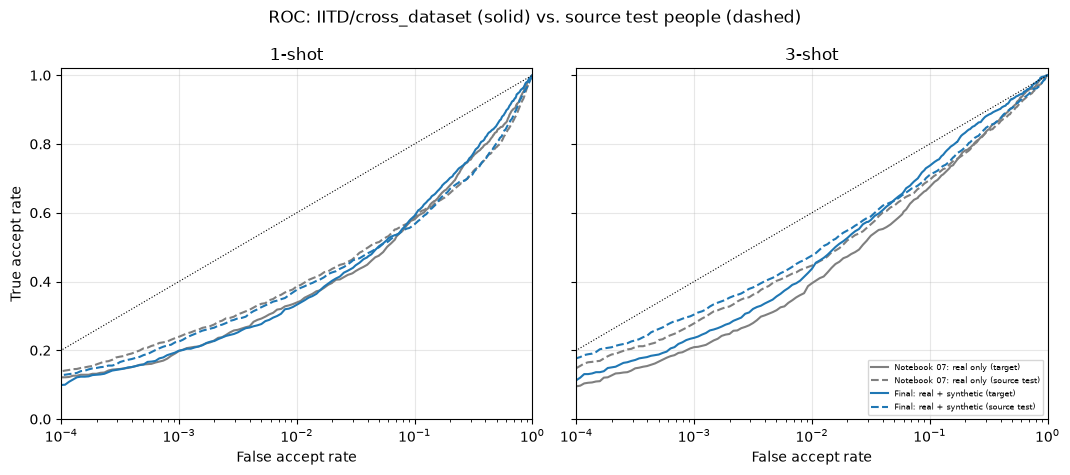

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_roc_IITD__cross_dataset.png


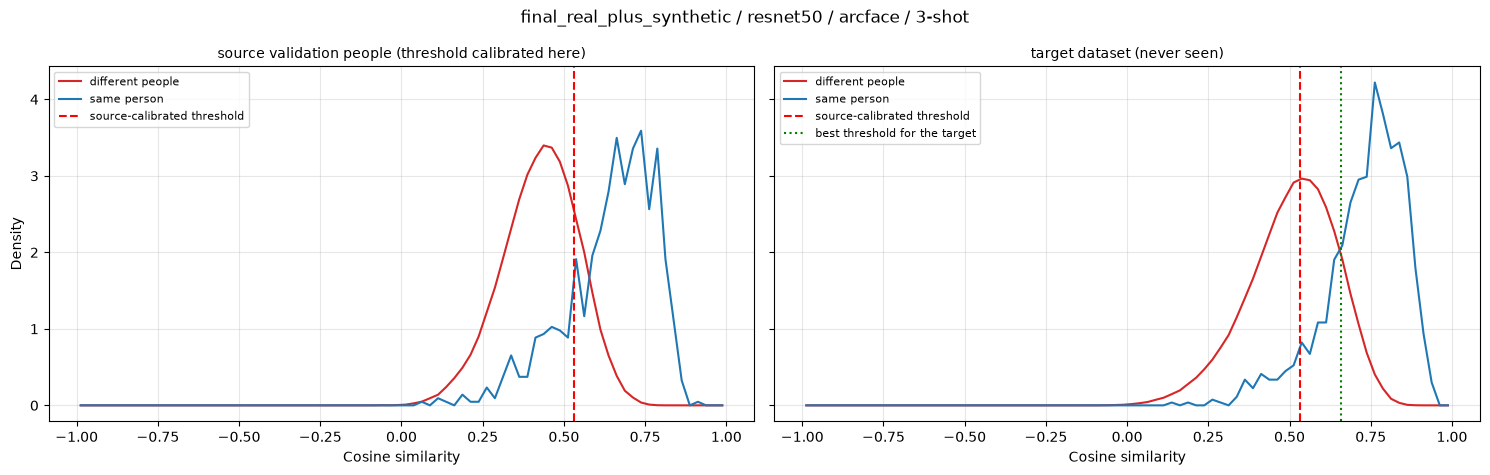

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_score_distributions.png


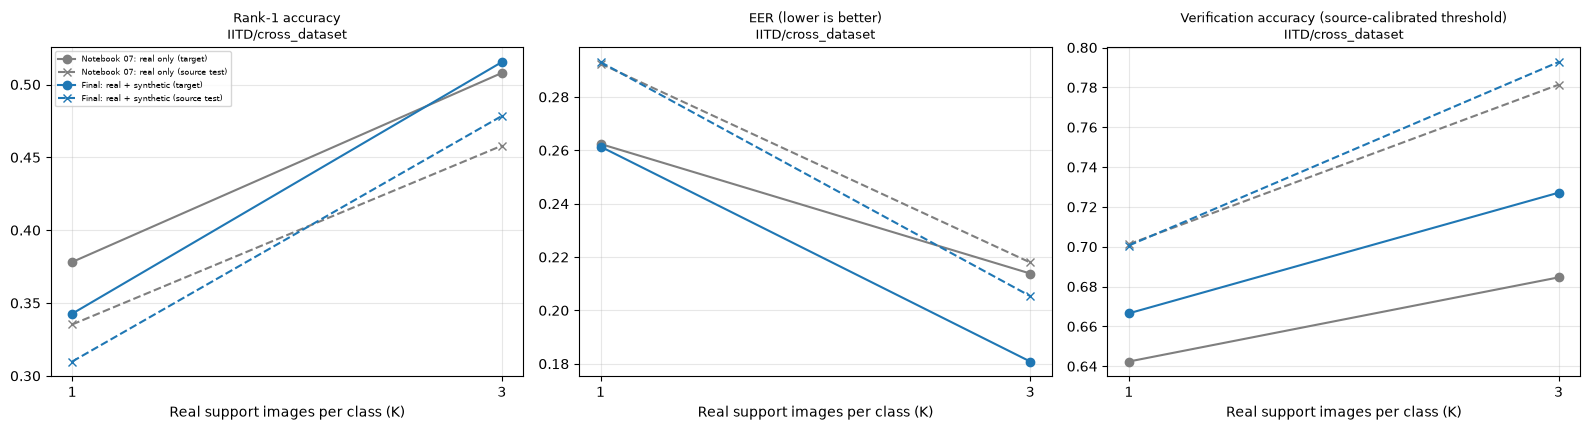

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest\cross_dataset_metrics_vs_shots.png


In [16]:
# ============================================================
# 14. Plots
# ============================================================

group_colors = {"baseline_real_only": "tab:gray", "baseline_traditional_aug": "tab:orange",
                "control_real_only": "tab:green", "final_real_plus_synthetic": "tab:blue"}
source_test_name = f"{source_dataset}/test"
target_sets = sorted(target_headline["eval_set"].unique())
shots_plotted = sorted(target_headline["shot"].unique())

# ---- 1. ROC curves of the chosen models ----
chosen_configs = set(zip(chosen["group"], chosen["family"], chosen["data_variant"], chosen["loss_variant"],
                         chosen["backbone"], chosen["shot"]))
roc_points["config"] = list(zip(roc_points["group"], roc_points["family"], roc_points["data_variant"],
                                roc_points["loss_variant"], roc_points["backbone"], roc_points["shot"]))
roc_chosen = roc_points[roc_points["config"].map(lambda c: c in chosen_configs)]
roc_mean = roc_chosen.groupby(["group", "shot", "eval_set", "fpr"], as_index=False)["tpr"].mean()

for target_set in target_sets:
    fig, axes = plt.subplots(1, len(shots_plotted), figsize=(5.4 * len(shots_plotted), 4.8), sharey=True, squeeze=False)

    for ax, shot in zip(axes[0], shots_plotted):
        for group in GROUP_ORDER:
            for eval_set, style, where in [(target_set, "-", "target"), (source_test_name, "--", "source test")]:
                curve = roc_mean[(roc_mean["group"] == group) & (roc_mean["shot"] == shot)
                                 & (roc_mean["eval_set"] == eval_set) & (roc_mean["fpr"] > 0)]
                if len(curve):
                    ax.plot(curve["fpr"], curve["tpr"], style, color=group_colors[group], label=f"{GROUP_LABELS[group]} ({where})")

        ax.plot([1e-5, 1], [1e-5, 1], ":", color="black", linewidth=0.8)
        ax.set_xscale("log")
        ax.set_xlim(1e-4, 1)
        ax.set_ylim(0, 1.02)
        ax.set_title(f"{shot}-shot")
        ax.set_xlabel("False accept rate")
        ax.grid(alpha=0.3)

    axes[0, 0].set_ylabel("True accept rate")
    axes[0, -1].legend(fontsize=6, loc="lower right")
    plt.suptitle(f"ROC: {target_set} (solid) vs. source test people (dashed)", fontsize=12)
    plt.tight_layout()
    path = RESULTS_DIR / f"cross_dataset_roc_{safe_name(target_set)}.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

# ---- 2. score distributions of the chosen final model ----
plot_group = "final_real_plus_synthetic" if "final_real_plus_synthetic" in set(chosen["group"]) else chosen["group"].iloc[0]
plot_shot = int(chosen[chosen["group"] == plot_group]["shot"].max())
plot_config = chosen[(chosen["group"] == plot_group) & (chosen["shot"] == plot_shot)].iloc[0]
plot_record = next((r for r in records if r["family"] == plot_config["family"] and r["data_variant"] == plot_config["data_variant"]
                    and r["loss_variant"] == plot_config["loss_variant"] and r["backbone"] == plot_config["backbone"]
                    and r["shot"] == plot_shot), None)

if plot_record is not None:
    target_set = target_sets[0]
    rows = pd.DataFrame(plot_record["metrics"]).set_index("eval_set")
    centers = (HISTOGRAM_EDGES[:-1] + HISTOGRAM_EDGES[1:]) / 2.0
    width = HISTOGRAM_EDGES[1] - HISTOGRAM_EDGES[0]
    source_threshold = plot_record["source_thresholds"]["eer"]

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    for ax, name, title in [(axes[0], f"{source_dataset}/val", "source validation people (threshold calibrated here)"),
                            (axes[1], target_set, "target dataset (never seen)")]:
        histogram = plot_record["histograms"].get(name)
        if histogram is None:
            continue
        for key, label, color in [("impostor", "different people", "tab:red"), ("genuine", "same person", "tab:blue")]:
            counts = np.array(histogram[key], dtype=float)
            ax.plot(centers, counts / max(counts.sum(), 1.0) / width, color=color, label=label)
        ax.axvline(source_threshold, color="red", linestyle="--", label="source-calibrated threshold")
        if name == target_set and np.isfinite(rows.loc[name, "thr_oracle"]):
            ax.axvline(rows.loc[name, "thr_oracle"], color="green", linestyle=":", label="best threshold for the target")
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("Cosine similarity")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

    axes[0].set_ylabel("Density")
    plt.suptitle(f"{plot_config['group']} / {plot_config['backbone']} / {plot_config['loss_variant']} / {plot_shot}-shot", fontsize=12)
    plt.tight_layout()
    path = RESULTS_DIR / "cross_dataset_score_distributions.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", path)

# ---- 3. metrics versus shots ----
panels = [("rank1_acc", "Rank-1 accuracy"), ("eer", "EER (lower is better)"),
          ("verification_acc_src_eer", "Verification accuracy (source-calibrated threshold)")]

fig, axes = plt.subplots(len(target_sets), 3, figsize=(16, 4.4 * len(target_sets)), squeeze=False)
for row, target_set in enumerate(target_sets):
    for col, (column, title) in enumerate(panels):
        ax = axes[row, col]
        for group in GROUP_ORDER:
            cross = headline[(headline["group"] == group) & (headline["eval_set"] == target_set)].sort_values("shot")
            inside = headline[(headline["group"] == group) & (headline["eval_set"] == source_test_name)].sort_values("shot")
            if len(cross):
                ax.plot(cross["shot"], cross[column], "-", marker="o", color=group_colors[group], label=f"{GROUP_LABELS[group]} (target)")
            if len(inside):
                ax.plot(inside["shot"], inside[column], "--", marker="x", color=group_colors[group], label=f"{GROUP_LABELS[group]} (source test)")
        ax.set_xticks(shots_plotted)
        ax.set_xlabel("Real support images per class (K)")
        ax.set_title(f"{title}\n{target_set}", fontsize=9)
        ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=6)
plt.tight_layout()
path = RESULTS_DIR / "cross_dataset_metrics_vs_shots.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", path)

## 15. Sanity checks

**Stop the notebook if:**
- a planned model is missing from the results, or failed its leakage guard (a model must never have seen the target dataset);
- an evaluated model has no target evaluation set, or its target Rank-1 / EER are not finite;
- a verification accuracy is outside `[0, 1]`, or a source-calibrated accuracy is **higher** than the oracle (impossible: the oracle is the best threshold on the same scores).

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- the numbers recomputed here differ from the numbers stored by Notebooks 07 and 13 (they should agree to rounding);
- a model's target Rank-1 is not above twice chance;
- the source-calibrated threshold is missing (no validation identities);
- the source-calibrated accuracy is more than 0.1 below the oracle (the threshold does not transfer);
- the final model is **not** better than a reference on the target (**this is a result, not an error**: report it honestly);
- the chosen final model differs from the best model of Notebook 13.

In [17]:
# ============================================================
# 15. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected = {(e["family"], e["run_id"]) for e in entries}
present = set(zip(runs_table["family"], runs_table["run_id"]))
add_check("all planned models were evaluated", not (expected - present), f"{len(expected - present)} missing")
add_check("every model passed the leakage guard (trained on the source dataset only)", bool(runs_table["leakage_checks_passed"].all()))

cross = results[results["kind"] == "cross_dataset"]
models_with_target = set(zip(cross["family"], cross["run_id"]))
add_check("every evaluated model has a target evaluation set", present <= models_with_target, f"{len(present - models_with_target)} without")
add_check("target Rank-1 and EER are finite", bool(np.isfinite(cross[["rank1_acc", "eer"]].to_numpy()).all()))

accuracy_columns_checked = ["verification_acc_src_eer", "verification_acc_src_far", "verification_acc_oracle"]
values = results[accuracy_columns_checked].to_numpy()
finite_values = values[np.isfinite(values)]
add_check("verification accuracies lie in [0, 1]", bool(((finite_values >= 0) & (finite_values <= 1)).all()))

for column in ["verification_acc_src_eer", "verification_acc_src_far"]:
    comparable = results.dropna(subset=[column, "verification_acc_oracle"])
    add_check(f"the oracle is never worse than {column} (it is the best threshold on the same scores)",
              bool((comparable["verification_acc_oracle"] + 1e-9 >= comparable[column]).all()))

near_chance = cross[cross["rank1_acc"] <= 2 * cross["chance_rank1"]]
add_check("target Rank-1 is more than twice chance everywhere", len(near_chance) == 0,
          f"{len(near_chance)} of {len(cross)} results are near chance", critical=False)

missing_threshold = cross[~np.isfinite(cross["thr_src_eer"])]
add_check("a source-calibrated threshold exists for every target result", len(missing_threshold) == 0,
          f"{len(missing_threshold)} without (no source validation identities?)", critical=False)

transfer = cross.dropna(subset=["verification_acc_src_eer", "verification_acc_oracle"])
lost = transfer[transfer["verification_acc_oracle"] - transfer["verification_acc_src_eer"] > 0.1]
add_check("the source-calibrated threshold transfers (within 0.1 of the best threshold)", len(lost) == 0,
          f"{len(lost)} of {len(transfer)} results lose more than 0.1", critical=False)

# the numbers recomputed here must equal the numbers stored by Notebooks 07 and 13
stored_parts = []
if BASELINE_RESULTS_PATH.exists():
    stored = pd.read_csv(BASELINE_RESULTS_PATH, usecols=["run_id", "eval_set", "rank1_acc", "eer"])
    stored["family"] = "baseline"
    stored_parts.append(stored)
if FINAL_RESULTS_PATH.exists():
    stored = pd.read_csv(FINAL_RESULTS_PATH, usecols=["run_id", "eval_set", "rank1_acc", "eer"])
    stored["family"] = "final"
    stored_parts.append(stored)

if stored_parts:
    merged = results.merge(pd.concat(stored_parts, ignore_index=True), on=["family", "run_id", "eval_set"], suffixes=("", "_stored"))
    if len(merged):
        difference = max(float((merged["rank1_acc"] - merged["rank1_acc_stored"]).abs().max()),
                         float((merged["eer"] - merged["eer_stored"]).abs().max()))
        add_check("Rank-1 and EER agree with the numbers stored by Notebooks 07 and 13", difference < 1e-3,
                  f"largest difference {difference:.2e} over {len(merged)} results", critical=False)
    else:
        print("NOTE: the stored Notebook 07 / 13 results have no matching rows; the agreement check was skipped.")
else:
    print("NOTE: the stored Notebook 07 / 13 results were not found; the agreement check was skipped.")

# the final model against the references (a result, not an error)
if len(comparison):
    for reference in references:
        column = f"eer_change_vs_{reference}"
        if column in comparison.columns:
            worse = comparison[comparison[column] >= 0]
            add_check(f"the final model has a lower target EER than {reference} (a result, not an error)", len(worse) == 0,
                      f"{len(worse)} of {len(comparison)} comparisons are not better", critical=False)

# the model chosen here for the final group should be the best model of Notebook 13 (same rule)
if FINAL_BEST_PATH.exists():
    nb13_best = pd.read_csv(FINAL_BEST_PATH)
    mine = chosen[chosen["group"] == "final_real_plus_synthetic"].set_index("shot")
    differing = [int(s) for s in nb13_best["shot"]
                 if int(s) in mine.index and (nb13_best.set_index("shot").loc[s, "backbone"] != mine.loc[int(s), "backbone"]
                                              or nb13_best.set_index("shot").loc[s, "loss_variant"] != mine.loc[int(s), "loss_variant"])]
    add_check("the chosen final model equals the best model of Notebook 13", not differing,
              f"different for shots {differing}", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "cross_dataset_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "cross_dataset_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical cross-dataset checks failed: {failed_names}"
print("\nCross-dataset sanity checks completed with no critical failures.")

[PASS] all planned models were evaluated  (0 missing)
[PASS] every model passed the leakage guard (trained on the source dataset only)
[PASS] every evaluated model has a target evaluation set  (0 without)
[PASS] target Rank-1 and EER are finite
[PASS] verification accuracies lie in [0, 1]
[PASS] the oracle is never worse than verification_acc_src_eer (it is the best threshold on the same scores)
[PASS] the oracle is never worse than verification_acc_src_far (it is the best threshold on the same scores)
[PASS] target Rank-1 is more than twice chance everywhere  (0 of 6 results are near chance)
[PASS] a source-calibrated threshold exists for every target result  (0 without (no source validation identities?))
[WARN] the source-calibrated threshold transfers (within 0.1 of the best threshold)  (3 of 6 results lose more than 0.1)
[WARN] Rank-1 and EER agree with the numbers stored by Notebooks 07 and 13  (largest difference 1.87e-03 over 18 results)
[PASS] the final model has a lower target

## 16. Final outputs

At the end of Notebook 14, the project should contain:

```text
results/cross_dataset_evaluation/
├── cross_dataset_report.csv             the report: Rank-1, verification accuracy, EER, TAR @ FAR (chosen models)
├── cross_dataset_comparison.csv         final model vs. baselines and control
├── cross_dataset_domain_gap.csv         target minus source-test, per kind of model
├── cross_dataset_results.csv            every metric, every model, every evaluation set
├── cross_dataset_accuracy.csv, cross_dataset_verification.csv, cross_dataset_roc.csv
├── cross_dataset_chosen_models.csv, cross_dataset_runs.csv, cross_dataset_sanity_checks.csv
├── runs/                                one JSON record per evaluated model
└── cross_dataset_roc_<target>.png, cross_dataset_score_distributions.png, cross_dataset_metrics_vs_shots.png
```

In [18]:
# ============================================================
# 16. Final output listing
# ============================================================

print("Notebook 14 output directory:")
print(RESULTS_DIR)

print("\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nRun records: {len(list(RUNS_DIR.glob('*.json')))} | models evaluated: {len(runs_table)}")
print("\nNotebook 14 completed.")

Notebook 14 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\cross_dataset_evaluation_quicktest

Top-level generated files:
- cross_dataset_accuracy.csv
- cross_dataset_chosen_models.csv
- cross_dataset_comparison.csv
- cross_dataset_domain_gap.csv
- cross_dataset_metrics_vs_shots.png
- cross_dataset_report.csv
- cross_dataset_results.csv
- cross_dataset_roc.csv
- cross_dataset_roc_IITD__cross_dataset.png
- cross_dataset_runs.csv
- cross_dataset_sanity_checks.csv
- cross_dataset_score_distributions.png
- cross_dataset_verification.csv

Run records: 6 | models evaluated: 6

Notebook 14 completed.


## 17. What this notebook hands to the rest of the project

```text
Notebooks 07 and 13                Notebook 14                          Notebooks 15 - 18
Trained recognizers        --->    Cross-dataset evaluation:     --->   15: explainability   16: ablations
(source dataset only)              CASIA -> unseen dataset              17: tables and figures
                                                                        18: significance tests
```

### How the outputs are used

| Notebook | Use |
|---|---|
| **15 Explainability** | The `domain_gap` table and the score-distribution figure show *where* a model loses (shifted scores or lost separation); the models to explain are listed in `cross_dataset_chosen_models.csv` |
| **16 Ablations** | Re-run Notebook 13 with other settings, then re-run this notebook: new checkpoints are picked up automatically, finished evaluations are skipped |
| **17 Performance comparison** | `cross_dataset_report.csv` has the columns the paper's cross-dataset table needs (Rank-1, verification accuracy, EER, TAR @ FAR); `cross_dataset_roc.csv` the ROC curves. State the **threshold rule** (`verification_acc_src_eer`) and never report the oracle accuracy as a result |
| **18 Statistical significance** | `cross_dataset_results.csv` keeps every seed; use several seeds, and resample **identities** (not images) for the confidence intervals, because the target has few people |

### Rules that keep the comparison honest

1. The target dataset is used for **scoring only**: never to choose a model, a backbone, a threshold, or any hyperparameter. The notebook chooses with the source validation people, and checks from each checkpoint that the model never saw the target.
2. Report the verification accuracy at the **source-calibrated threshold**. The oracle accuracy is an upper bound.
3. State that the evaluation is **one direction** (source to target) and that the target has fewer people than the source.
4. Compare the final model with the **traditional-augmentation baseline** as well as with real-only training, and with the same-code control if it was trained.
5. Report `CONFIG_HASH` and the seeds with every number.

### Reading the results

| What you see | Likely cause | What to try |
|---|---|---|
| Large drop of Rank-1 and a high `eer_ratio` | The model relies on source-specific cues (sensor, illumination) | Compare the final model with the baselines; try stronger appearance augmentation; check the synthetic images for source-specific artefacts |
| EER barely changes but `verification_acc_src_eer` is far below the oracle | The score distributions shifted: the threshold does not transfer | Report both; consider calibrating the threshold on the target in deployment (a different protocol, to be stated explicitly) |
| `dprime` drops a lot | Same-person and different-person scores overlap more on the target | See the score-distribution figure |
| The final model is not better on the target | The synthetic images add little that transfers | Check Notebooks 11 and 12 (acceptance, diversity); compare with the control |
| The numbers differ from Notebooks 07 / 13 | Different GPU or `MIXED_PRECISION` setting, or a changed checkpoint | Re-run with the same settings; the check in section 15 shows the size of the difference |